## Setup Libraries

In [1]:
!pip install -q pytabkit

In [12]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [13]:
import random
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from importlib.metadata import version
from time import time

from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import KBinsDiscretizer, TargetEncoder
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

import torch
import pytabkit
from pytabkit import RealMLP_TD_Classifier

warnings.filterwarnings('ignore')
print("PyTorch  version:", torch.__version__)
print("PyTabKit version:", version("pytabkit"))

pd.set_option('display.max_columns', 100)

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

PyTorch  version: 2.11.0+cu130
PyTabKit version: 1.8.0


In [15]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})

## Load Data

In [3]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

n_unique = train.nunique().sort_values()
n_unique

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

## Preprocess Features

In [4]:
%%time
## NB: Original feature engineering

ID = 'id'
TARGET = 'is_fraud'

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print('-'*40)
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'bool']).columns.tolist()
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
def feature_engineering(df, fit=False):
    # Categorize numericals
    for col in num_cols:
        cat_name = f"{col}_cat_"
        if fit:
            codes, uniques = np.floor(df[col]).factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = np.floor(df[col]).map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols

X, new_cat_cols, new_num_cols = feature_engineering(X, fit=True)
X_test, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols

print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")
print('-'*40)

----------------------------------------
X      init shape: (699960, 24)
X_test init shape: (299984, 24) 

init len(cat_cols): 11
init len(num_cols): 13 

len(new_cat_cols): 13
len(new_num_cols): 0 

prep len(cat_cols): 24
prep len(num_cols): 13 

X      prep shape: (699960, 37)
X_test prep shape: (299984, 37) 

----------------------------------------
CPU times: user 415 ms, sys: 54 ms, total: 469 ms
Wall time: 466 ms


In [5]:
X.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_cat_,hours_since_last_txn_cat_,txn_count_last_24h_cat_,distance_from_home_km_cat_,card_age_months_cat_,customer_age_cat_,account_balance_usd_cat_,cvv_retry_count_cat_,velocity_score_cat_,time_of_day_hour_cat_,day_of_week_cat_,merchant_risk_score_cat_,prior_disputes_cat_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0,0,0,0,0,0,0,0,0,0,0,0,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,1,1,1,1,1,1,1,0,1,1,1,0,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,2,1,2,2,2,2,2,0,2,2,2,1,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,3,2,2,2,0,3,3,0,3,3,0,2,0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,4,3,2,3,3,4,4,0,4,4,3,3,0


In [6]:
# %%time

# ID = 'id'
# TARGET = 'is_fraud'

# X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
# y = train[TARGET]
# X_test = test.drop([ID], axis=1); test_id = test[ID]

# del train, test
# print("X      init shape:", X.shape)
# print("X_test init shape:", X_test.shape, "\n")

# cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
# num_cols = X.select_dtypes(exclude=['object', 'bool']).columns.tolist()
# print("init len(cat_cols):", len(cat_cols))
# print("init len(num_cols):", len(num_cols), "\n")

# category_map = {}
# important_combos = [
#     ('Class', 'Type of Travel', 'Gender'),
#     ('Class', 'Type of Travel', 'Age'),
#     ('Flight Distance', 'Departure/Arrival time convenient'),
# ]

# def feature_engineering(df, fit=False):
#     # Fill NaNs
#     for col in cat_cols:
#         df[col] = df[col].fillna("missing")
#     for col in num_cols:
#         df[col] = df[col].fillna(0.0)
    
#     # Categorize numericals
#     for col in num_cols:
#         cat_name = f"{col}_cat_"
#         if fit:
#             codes, uniques = df[col].factorize()
#             category_map[col] = uniques
#         else:
#             uniques = category_map[col]
#             code_map = {cat: i for i, cat in enumerate(uniques)}
#             codes = df[col].map(code_map).fillna(-1).astype('int32')
#         df[cat_name] = codes
#         df[cat_name] = df[cat_name].astype('category')

#     # Count encoding
#     for col in cat_cols + ['Leg room service']:
#         count_name = f"_{col}_count"
#         if fit:
#             count_map = df[col].value_counts()
#             category_map[count_name] = count_map
#         else:
#             count_map = category_map[count_name]
#         df[count_name] = df[col].map(count_map).fillna(0).astype('int32')

#     # Create interaction categories
#     combo_names = []
#     for cols in important_combos:
#         combo_name = '_'.join(cols) + '_'
#         combo_names.append(combo_name)
#         combo_series = df[cols[0]].astype(str)
#         for col in cols[1:]:
#             combo_series = combo_series + '_' + df[col].astype(str)
#         if fit:
#             codes, uniques = pd.factorize(combo_series, sort=False)
#             category_map[combo_name] = uniques
#         else:
#             uniques = category_map[combo_name]
#             code_map = {cat: i for i, cat in enumerate(uniques)}
#             codes = combo_series.map(code_map).fillna(-1).astype('int32')
#         df[combo_name] = codes
#         df[combo_name] = df[combo_name].astype('category') 

#     new_cat_cols = [col for col in df.columns if col.endswith('_')]
#     new_num_cols = [col for col in df.columns if col.startswith('_')]
#     return df, new_cat_cols, new_num_cols, combo_names

# X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
# X_test, _, _, _ = feature_engineering(X_test, fit=False)
# cat_cols += new_cat_cols; num_cols += new_num_cols
# print("len(new_cat_cols):", len(new_cat_cols))
# print("len(new_num_cols):", len(new_num_cols), "\n")

# print("prep len(cat_cols):", len(cat_cols))
# print("prep len(num_cols):", len(num_cols), "\n")
# print("X      prep shape:", X.shape)
# print("X_test prep shape:", X_test.shape, "\n")

## Config

In [7]:
## -- NB: original parameters --

params = {
    'random_state': 42,
    'verbosity': 2,
    'val_metric_name': '1-auc_ovr',

    'n_ens': 8,
    'n_epochs': 2,
    'batch_size': 288,
    'use_early_stopping': False,
    'early_stopping_additive_patience': 10,
    'early_stopping_multiplicative_patience': 1,

    'lr': 0.053,
    'wd': 0.015,
    'sq_mom': 0.988,
    'lr_sched': 'flat_anneal',
    'wd_sched': 'cos_log_15',
    'first_layer_lr_factor': 0.25,

    'embedding_size': 5,
    'max_one_hot_cat_size': 2,
    'hidden_sizes': [512, 256, 128],
    'act': 'silu',
    'p_drop': 0.05,
    'p_drop_sched': 'pow5',

    'plr_hidden_1': 16,
    'plr_hidden_2': 8,
    'plr_act_name': 'gelu',
    'plr_lr_factor': 0.1151,
    'plr_sigma': 0.75,

    'ls_eps': 0.01,
    'ls_eps_sched': 'sqrt_cos',

    'add_front_scale': False,
    'bias_init_mode': 'neg-uniform-dynamic-2',
    'tfms': ['one_hot', 'median_center', 'robust_scale',
             'smooth_clip', 'embedding', 'l2_normalize'],
}


## -- Custom parameters --
# params = {
#     'random_state': 42,
#     'verbosity': 2,
#     'val_metric_name': '1-auc_ovr',

#     'n_ens': 8,
#     'n_epochs': 3,
#     'batch_size': 256,
#     'use_early_stopping': False,
#     'early_stopping_additive_patience': 10,
#     'early_stopping_multiplicative_patience': 1,

#     'lr': 0.053,
#     'wd': 0.015,
#     'sq_mom': 0.988,
#     'lr_sched': 'flat_anneal',
#     'wd_sched': 'cos_log_15',
#     'first_layer_lr_factor': 0.25,

#     'embedding_size': 5,
#     'max_one_hot_cat_size': 15,
#     'hidden_sizes': [512, 256, 128],
#     'act': 'silu',
#     'p_drop': 0.05,
#     'p_drop_sched': 'pow5',

#     'plr_hidden_1': 16,
#     'plr_hidden_2': 8,
#     'plr_act_name': 'gelu',
#     'plr_lr_factor': 0.1151,
#     'plr_sigma': 2.33,

#     'ls_eps': 0.01,
#     'ls_eps_sched': 'sqrt_cos',

#     'add_front_scale': False,
#     'bias_init_mode': 'neg-uniform-dynamic-2',
#     'tfms': ['one_hot', 'median_center', 'robust_scale',
#              'smooth_clip', 'embedding', 'l2_normalize'],
# }

params

{'random_state': 42,
 'verbosity': 2,
 'val_metric_name': '1-auc_ovr',
 'n_ens': 8,
 'n_epochs': 2,
 'batch_size': 288,
 'use_early_stopping': False,
 'early_stopping_additive_patience': 10,
 'early_stopping_multiplicative_patience': 1,
 'lr': 0.053,
 'wd': 0.015,
 'sq_mom': 0.988,
 'lr_sched': 'flat_anneal',
 'wd_sched': 'cos_log_15',
 'first_layer_lr_factor': 0.25,
 'embedding_size': 5,
 'max_one_hot_cat_size': 2,
 'hidden_sizes': [512, 256, 128],
 'act': 'silu',
 'p_drop': 0.05,
 'p_drop_sched': 'pow5',
 'plr_hidden_1': 16,
 'plr_hidden_2': 8,
 'plr_act_name': 'gelu',
 'plr_lr_factor': 0.1151,
 'plr_sigma': 0.75,
 'ls_eps': 0.01,
 'ls_eps_sched': 'sqrt_cos',
 'add_front_scale': False,
 'bias_init_mode': 'neg-uniform-dynamic-2',
 'tfms': ['one_hot',
  'median_center',
  'robust_scale',
  'smooth_clip',
  'embedding',
  'l2_normalize']}

## Train K-Fold

In [8]:
class CFG:
    FOLDS = 5
    SEED = 42
    TE = True if 'combo_names' in globals() else False

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = 'pytab_RealMLP'
print(f"\n🚀 Training {model_name}_({X.shape[1]}) with {FOLDS } Folds")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_scores = []
fold_times = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()  

    print()
    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # -------------------------------------------------------------
    # Target encoding
    if CFG.TE:
        smooth = 'auto'
        te_cols = combo_names
        TE = TargetEncoder(cv=5, smooth=smooth, shuffle=True, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = [
            # 'Class_Type of Travel_Age_',
            # 'Flight Distance_Departure/Arrival time convenient_',
        ]

        X_trn = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)

    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}\n")

    model = RealMLP_TD_Classifier(**params)

    seeder = 42 #+ (fold-1)
    model.random_state = seeder

    model.fit(X_trn, y_trn, X_val, y_val) #, cat_col_names=cat_cols

    val_preds = model.predict_proba(X_val)[:, 1]
    fold_test_preds = model.predict_proba(X_tst)[:, 1]

    oof_preds[val_idx] = val_preds
    test_preds += fold_test_preds

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} | AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed = {seeder}, time = {ff}mins ]")
    torch.cuda.empty_cache()

test_preds /= FOLDS

model_name = model_name + f"({X_trn.shape[1]})"

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")
for i, s in enumerate(fold_scores, 1):
    print(f" • Fold {i} AUC: {s}")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
# fold_results[f'iter'] = best_iterations
fold_results[f'time(min)'] = fold_times

print("-------------------------------------------------|")
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-------------------------------------------------|")

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.3g} mins\n")

del X_trn, y_trn


🚀 Training pytab_RealMLP_(37) with 5 Folds

### Fold 1/5
train=(559968, 37), valid=(139992, 37)

Columns classified as continuous: ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']
Columns classified as categorical: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt', 'amount_usd_cat_', 'hours_since_last_txn_cat_', 'txn_count_last_24h_cat_', 'distance_from_home_km_cat_', 'card_age_months_cat_', 'customer_age_cat_', 'account_balance_usd_cat_', 'cvv_retry_count_cat_', 'velocity_score_cat_', 'time_of_day_hour_cat_', 'day_of_week_cat_', 'merchant_risk_score_cat_', 'prior_disputes_cat_']
Epoch 1/2: val 1-auc_ovr = 0.052714
Ep

## Evaluation and Submission

In [9]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-' * 20)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-' * 20)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

--------------------
pytab_RealMLP(37)_94891
--------------------
6.07 mins



,auc,time(min)
fold 1,0.94837,1.22
fold 2,0.95002,1.20
fold 3,0.95375,1.21
fold 4,0.94884,1.21
fold 5,0.94358,1.22


In [10]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000270
1,699961,0.000071
2,699962,0.106330
3,699963,0.002127
4,699964,0.001431


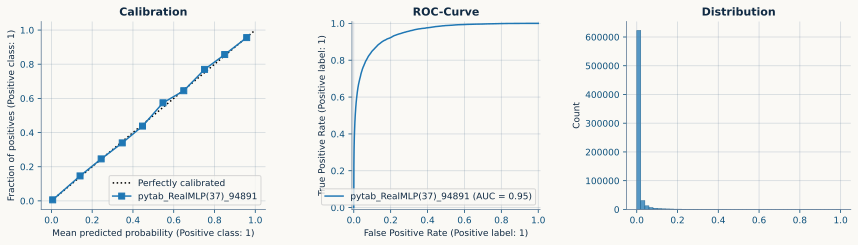

In [16]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12, 3.5)) 
CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()

In [ ]:
# !rm -r /kaggle/working